# Technical Appendix: Baseline Implementation (Phase 2, Option A)
**Paper:** Kanani et al. (2023), *An AI-enabled ensemble method for rainfall forecasting using Long-Short Term Memory*,
Mathematical Biosciences and Engineering 20(5).

**Task.** Build simple baseline models on the paper's data set (Rain in Australia, 49 stations) and compare them with the
authors' reported results. Two baselines are used: **Random Forest** and **XGBoost**. Each is trained twice:
* **A, default settings:** the library defaults, as an untuned first attempt.
* **B, regularised:** settings chosen to reduce over-fitting, picked using the validation year only.

**Targets.** Classification: will it rain tomorrow (yes/no). Regression: how many millimetres will fall tomorrow.

**How to run.** Put `weatherAUS.csv` in the same folder, then run all cells from top to bottom (about 30 minutes on 2 CPU cores).
Required packages: numpy, pandas, matplotlib, scikit-learn, xgboost, imbalanced-learn (only for the leakage proof in section 16).
**Evaluation design (different from the paper).** The paper split random rows 80/20 after balancing, so test days sat between
training days. Here the split is chronological, and the test period is used only once, at the end:

| Part | Period | Used for |
|---|---|---|
| Train | up to 2014 | fitting the models |
| Validation | 2015 | early stopping, calibration, decision threshold, choosing the B settings |
| Test | 2016-01-01 to 2017-06-25 | final scores, computed once |

**Proof that the design matters.** Section 16 re-creates the paper's evaluation recipe (IQR deletion, SMOTE before the split, a random split) and
changes one choice at a time, to show how much of the paper's accuracy comes from leakage and not from the model.

In [32]:
# Packages: numpy, pandas, matplotlib, scikit-learn, xgboost, imbalanced-learn (only for the SMOTE steps in section 16).
# If one is missing, run this once in its own cell and restart:   %pip install xgboost imbalanced-learn
import warnings

import matplotlib.pyplot as plt                      # plots
import numpy as np                                   # arrays and maths
import pandas as pd                                  # tables
import xgboost as xgb                                # gradient-boosted trees
from sklearn.calibration import calibration_curve   # points for the reliability plot
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression  # used for Platt calibration
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss, f1_score,
                             matthews_corrcoef, mean_absolute_error, mean_squared_error,
                             precision_recall_curve, precision_score, r2_score, recall_score,
                             roc_auc_score)

warnings.filterwarnings("ignore")                    # keep the output clean
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 42                                            # one seed for every random choice, so results can be repeated
np.random.seed(SEED)

# Period boundaries (chronological split)
TRAIN_END = pd.Timestamp("2014-12-31")      # last day of the training period
VAL_START = pd.Timestamp("2015-01-01")      # validation year
VAL_END = pd.Timestamp("2015-12-31")
TEST_START = pd.Timestamp("2016-01-01")     # test period runs to the end of the data
HISTORY_DAYS = 15                           # a row is usable only if the previous 15 days were all recorded

## 1. Load the data
The only changes to the raw file: `Yes/No` becomes `1/0`, and rows are sorted by station and date.

In [33]:
raw = pd.read_csv("weatherAUS.csv", parse_dates=["Date"])                  # read the file and parse the dates
raw["RainToday"] = raw["RainToday"].map({"No": 0.0, "Yes": 1.0})            # Yes/No to 1/0 (missing stays missing)
raw["RainTomorrow"] = raw["RainTomorrow"].map({"No": 0.0, "Yes": 1.0})
raw = raw.sort_values(["Location", "Date"]).reset_index(drop=True)          # each station's days in date order
assert not raw.duplicated(["Location", "Date"]).any()                       # one row per station and day
assert raw["Location"].nunique() == 49, (                                   # stop early if a smaller file is used
    f"Found {raw['Location'].nunique()} stations and {len(raw):,} rows, but the paper uses the full Kaggle "
    "'Rain in Australia' file (49 stations, 145,460 rows). Replace weatherAUS.csv with the full file.")

rain_rate = raw["RainTomorrow"].mean()                                      # share of days followed by rain
print(f"rows: {len(raw):,} | stations: {raw['Location'].nunique()} | {raw['Date'].min().date()} to {raw['Date'].max().date()}")
print(f"share of rainy days: {rain_rate:.3f}  ->  always predicting 'no rain' is already {1 - rain_rate:.1%} accurate")
raw.head()

rows: 145,460 | stations: 49 | 2007-11-01 to 2017-06-25
share of rainy days: 0.224  ->  always predicting 'no rain' is already 77.6% accurate


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-07-01,Adelaide,8.8,15.7,5.0,1.6,2.6,NW,48.0,SW,...,92.0,67.0,1017.4,1017.7,NaN,NaN,13.5,14.9,1.0,0.0
1,2008-07-02,Adelaide,12.7,15.8,0.8,1.4,7.8,SW,35.0,SSW,...,75.0,52.0,1022.4,1022.6,NaN,NaN,13.7,15.5,0.0,0.0
2,2008-07-03,Adelaide,6.2,15.1,0.0,1.8,2.1,W,20.0,NNE,...,81.0,56.0,1027.8,1026.5,NaN,NaN,9.3,13.9,0.0,0.0
3,2008-07-04,Adelaide,5.3,15.9,0.0,1.4,8.0,NNE,30.0,NNE,...,71.0,46.0,1028.7,1025.6,NaN,NaN,10.2,15.3,0.0,0.0
4,2008-07-05,Adelaide,9.8,15.4,0.0,NaN,0.9,N,30.0,NNE,...,56.0,67.0,1023.6,1020.2,NaN,NaN,11.3,13.8,0.0,NaN


### 1.1 Exploratory data analysis (EDA)
Before any cleaning, look at the raw table: its size, types, missing values, the target, and how the weather variables relate to rain tomorrow.

In [34]:
# EDA 1: size, column types and summary statistics of every numeric column
print(f"rows: {raw.shape[0]:,} | columns: {raw.shape[1]} | stations: {raw['Location'].nunique()}")
print(f"numeric columns: {raw.select_dtypes('number').shape[1]} | text columns: {raw.select_dtypes('object').shape[1]} | date column: 1")
raw.describe().T.round(2)

rows: 145,460 | columns: 23 | stations: 49
numeric columns: 18 | text columns: 4 | date column: 1


,count,mean,min,25%,50%,75%,max,std
Date,145460,2013-04-04 21:08:51.907053568,2007-11-01 00:00:00,2011-01-11 00:00:00,2013-06-02 00:00:00,2015-06-14 00:00:00,2017-06-25 00:00:00,NaN
MinTemp,143975.0,12.194034,-8.5,7.6,12.0,16.9,33.9,6.398495
MaxTemp,144199.0,23.221348,-4.8,17.9,22.6,28.2,48.1,7.119049
Rainfall,142199.0,2.360918,0.0,0.0,0.0,0.8,371.0,8.47806
Evaporation,82670.0,5.468232,0.0,2.6,4.8,7.4,145.0,4.193704
Sunshine,75625.0,7.611178,0.0,4.8,8.4,10.6,14.5,3.785483
WindGustSpeed,135197.0,40.03523,6.0,31.0,39.0,48.0,135.0,13.607062
WindSpeed9am,143693.0,14.043426,0.0,7.0,13.0,19.0,130.0,8.915375
WindSpeed3pm,142398.0,18.662657,0.0,13.0,19.0,24.0,87.0,8.8098
Humidity9am,142806.0,68.880831,0.0,57.0,70.0,83.0,100.0,19.029164


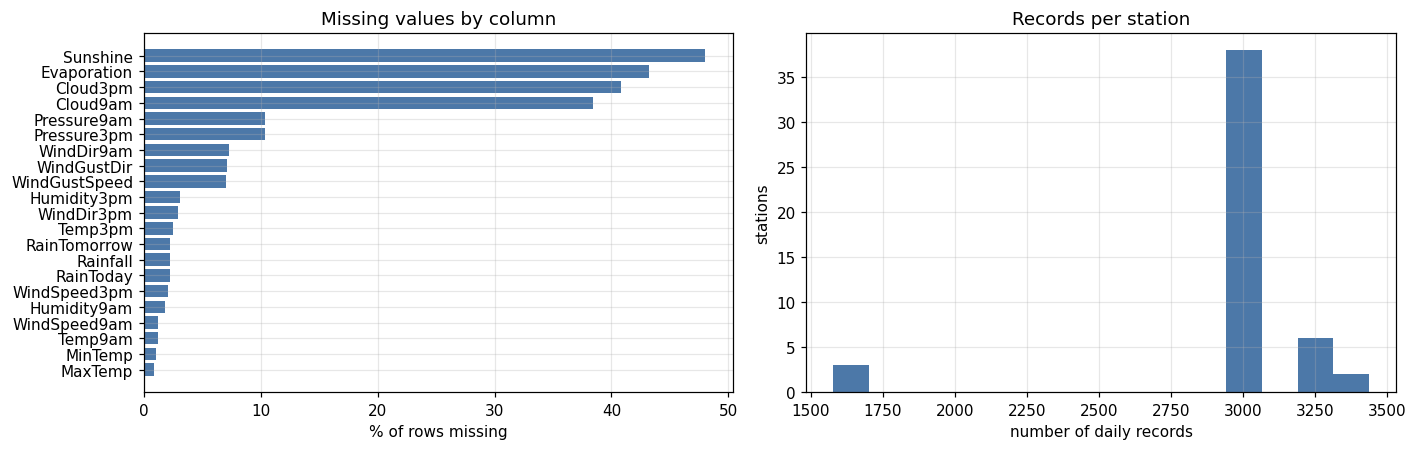

columns with more than 30 % missing: ['Sunshine', 'Evaporation', 'Cloud3pm', 'Cloud9am']
records per station: min 1,578 (Katherine), max 3,436 (Canberra)


In [35]:
# EDA 2: share of missing values in each column, and how many station records exist per station
missing = (raw.isna().mean() * 100).sort_values(ascending=False)
missing = missing[missing > 0]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].barh(missing.index, missing.values, color="#4C78A8")
axes[0].invert_yaxis()                                    # largest bar at the top
axes[0].set(title="Missing values by column", xlabel="% of rows missing")
records = raw["Location"].value_counts()
axes[1].hist(records.values, bins=15, color="#4C78A8")
axes[1].set(title="Records per station", xlabel="number of daily records", ylabel="stations")
plt.tight_layout()
plt.show()
print(f"columns with more than 30 % missing: {list(missing[missing > 30].index)}")
print(f"records per station: min {records.min():,} ({records.idxmin()}), max {records.max():,} ({records.idxmax()})")

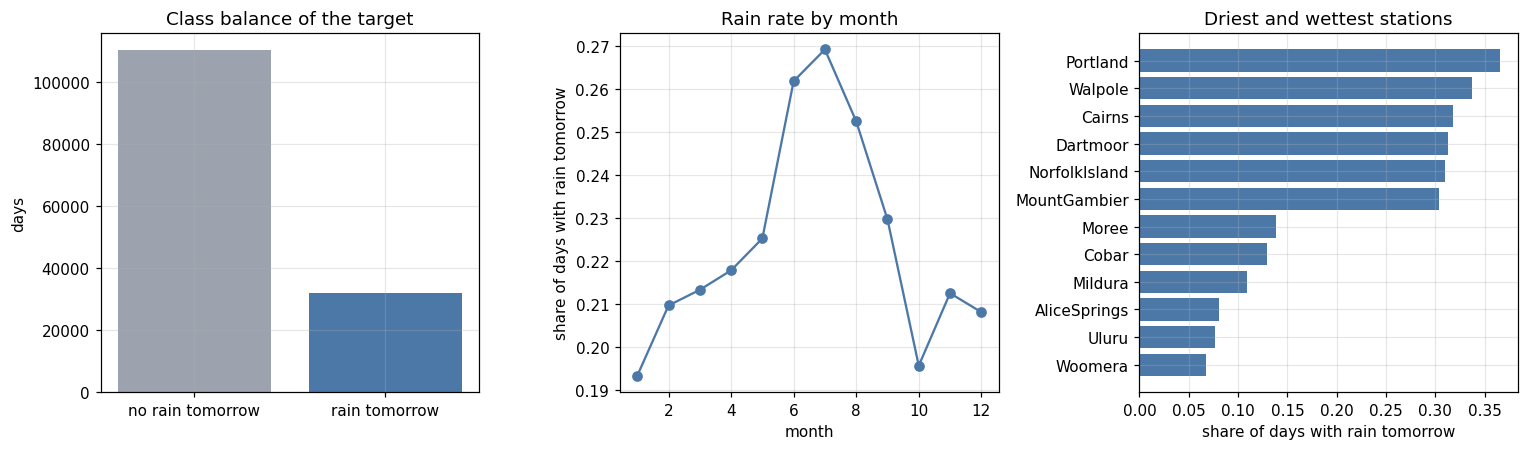

rain tomorrow on 22.4% of days | station rain rates range from 6.8% to 36.5%


In [36]:
# EDA 3: the target (RainTomorrow) and when and where it rains
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

target_counts = raw["RainTomorrow"].value_counts().sort_index()
axes[0].bar(["no rain tomorrow", "rain tomorrow"], target_counts.values, color=["#9CA3AF", "#4C78A8"])
axes[0].set(title="Class balance of the target", ylabel="days")

by_month = raw.groupby(raw["Date"].dt.month)["RainTomorrow"].mean()      # average rain rate for each calendar month
axes[1].plot(by_month.index, by_month.values, "o-", color="#4C78A8")
axes[1].set(title="Rain rate by month", xlabel="month", ylabel="share of days with rain tomorrow")

by_station = raw.groupby("Location")["RainTomorrow"].mean().sort_values()
extremes = pd.concat([by_station.head(6), by_station.tail(6)])            # six driest and six wettest stations
axes[2].barh(extremes.index, extremes.values, color="#4C78A8")
axes[2].set(title="Driest and wettest stations", xlabel="share of days with rain tomorrow")
plt.tight_layout()
plt.show()
print(f"rain tomorrow on {raw['RainTomorrow'].mean():.1%} of days | station rain rates range from {by_station.min():.1%} to {by_station.max():.1%}")

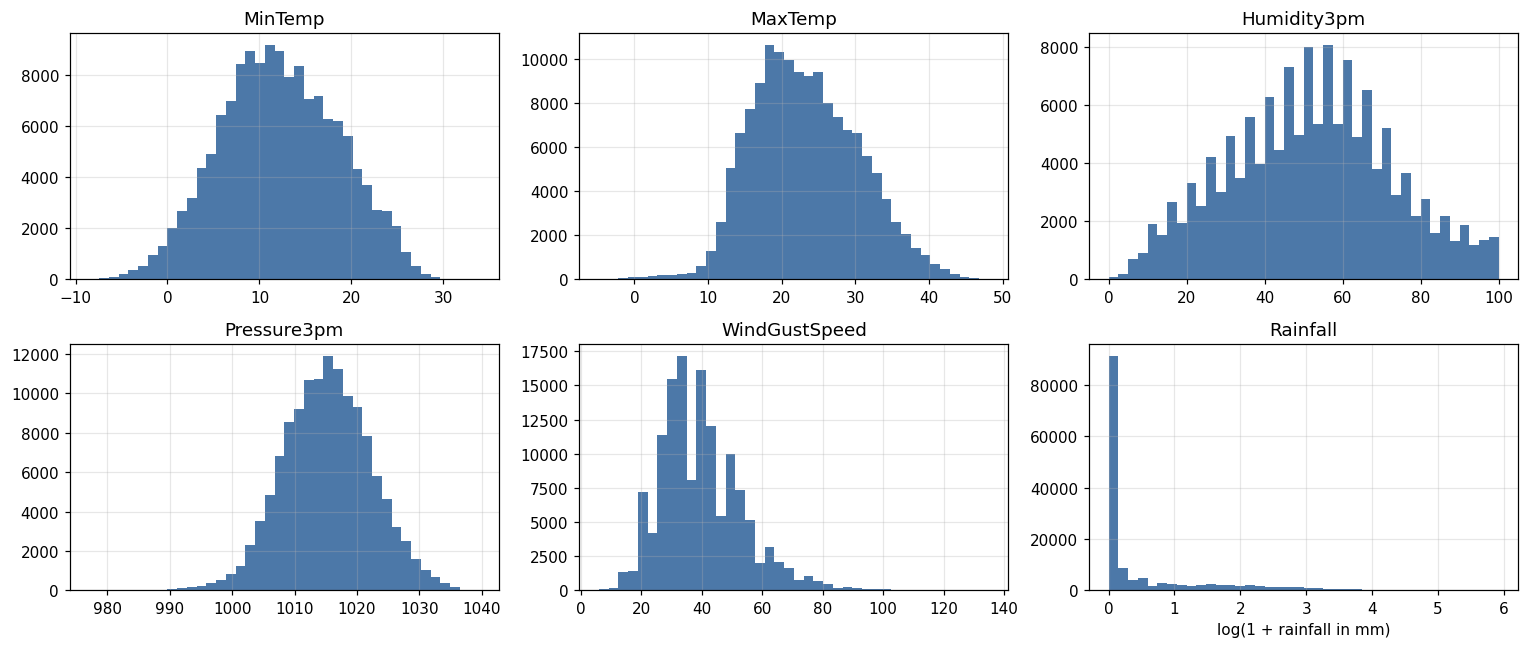

days with 0 mm of rain: 62.6% | 99th percentile: 37.4 mm | maximum: 371 mm
IQR upper fence for Rainfall (Q3 + 1.5 x IQR): 2.0 mm  ->  every heavier day would be deleted as an 'outlier'


In [37]:
# EDA 4: distribution of six key variables (Rainfall is shown on a log scale because it is very skewed)
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, col in zip(axes.ravel(), ["MinTemp", "MaxTemp", "Humidity3pm", "Pressure3pm", "WindGustSpeed", "Rainfall"]):
    values = raw[col].dropna()
    if col == "Rainfall":
        values = np.log1p(values)                                       # log(1 + mm), so that dry days (0 mm) stay at 0
        ax.set_xlabel("log(1 + rainfall in mm)")
    ax.hist(values, bins=40, color="#4C78A8")
    ax.set_title(col)
plt.tight_layout()
plt.show()

q1, q3 = raw["Rainfall"].quantile([0.25, 0.75])
print(f"days with 0 mm of rain: {(raw['Rainfall'] == 0).mean():.1%} | 99th percentile: {raw['Rainfall'].quantile(0.99):.1f} mm | maximum: {raw['Rainfall'].max():.0f} mm")
print(f"IQR upper fence for Rainfall (Q3 + 1.5 x IQR): {q3 + 1.5 * (q3 - q1):.1f} mm  ->  every heavier day would be deleted as an 'outlier'")

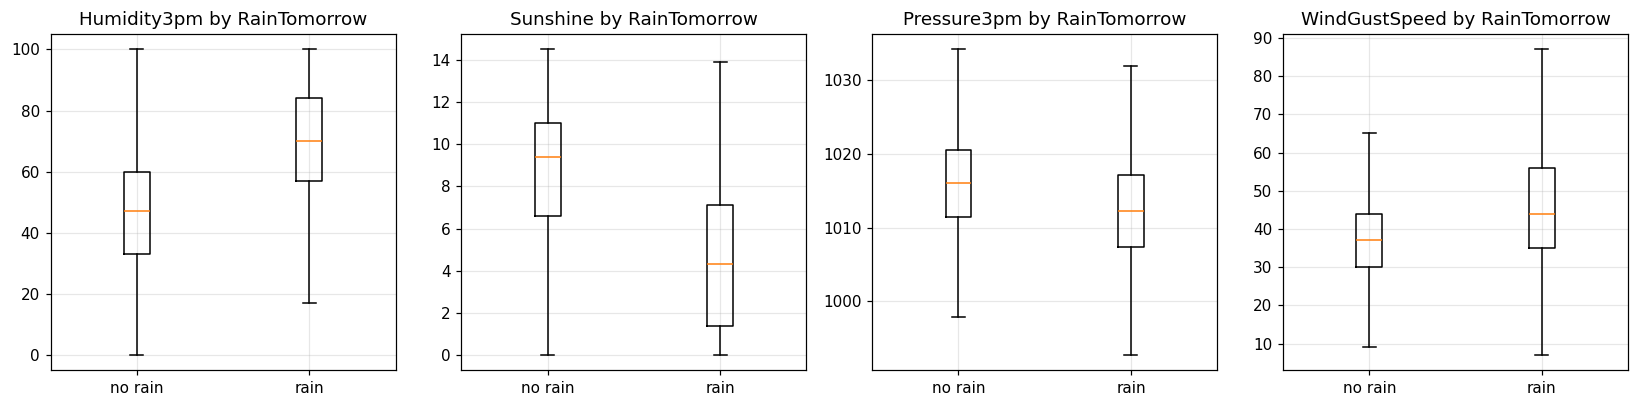

strongest correlations with RainTomorrow:
Sunshine      -0.451
Humidity3pm    0.446
Cloud3pm       0.382
Cloud9am       0.317
RainToday      0.313
Humidity9am    0.257


In [38]:
# EDA 5: how the main variables differ between days before rain and days before no rain, and how they correlate
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, col in zip(axes, ["Humidity3pm", "Sunshine", "Pressure3pm", "WindGustSpeed"]):
    groups = [raw.loc[raw["RainTomorrow"] == 0, col].dropna(), raw.loc[raw["RainTomorrow"] == 1, col].dropna()]
    ax.boxplot(groups, showfliers=False)                                # outliers hidden so the boxes stay readable
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["no rain", "rain"])
    ax.set_title(f"{col} by RainTomorrow")
plt.tight_layout()
plt.show()

numeric_cols = raw.select_dtypes("number").columns
corr = raw[numeric_cols].corr()["RainTomorrow"].drop("RainTomorrow").sort_values(key=abs, ascending=False)
print("strongest correlations with RainTomorrow:")
print(corr.head(6).round(3).to_string())

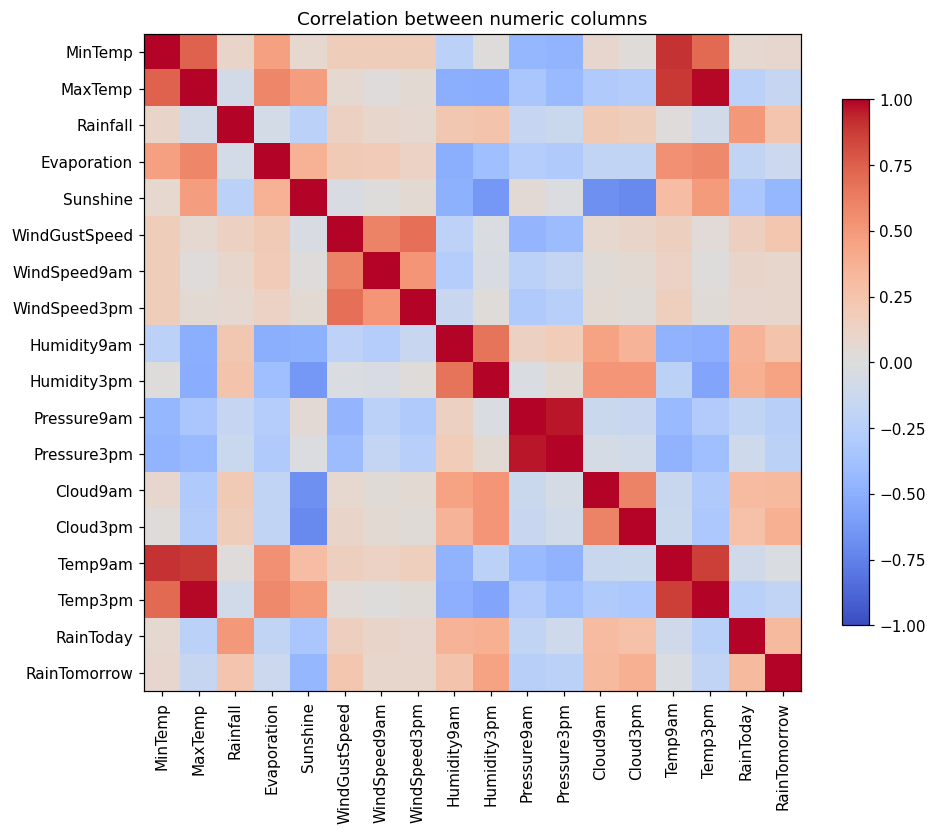

In [39]:
# EDA 6: correlation heatmap between all numeric columns (red = move together, blue = move in opposite directions)
corr_matrix = raw[numeric_cols].corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
image = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric_cols)))
ax.set_yticks(range(len(numeric_cols)))
ax.set_xticklabels(numeric_cols, rotation=90)
ax.set_yticklabels(numeric_cols)
ax.grid(False)
plt.colorbar(image, ax=ax, shrink=0.8)
plt.title("Correlation between numeric columns")
plt.tight_layout()
plt.show()

**Reading the EDA.**
* Sunshine, evaporation and the two cloud columns are missing for 38 to 48 % of rows, so the preprocessing adds a "was missing" flag for them.
* Only 22 % of days are followed by rain, so accuracy must be compared with the 77.6 % of "always no rain".
* Rainfall is extremely skewed (62.6 % zeros, a 371 mm maximum). The IQR rule would delete every day above 2 mm, which are real storms, so they are kept.
* Humidity, sunshine, pressure and cloud separate rain from no rain, which is why simple tree models can learn the task.

## 2. Remove physically impossible values
The paper deleted statistical outliers with the IQR rule, which removes real storms (the IQR limit for `Rainfall` is only about 2 mm).
Here only impossible values (for example humidity above 100 %) are set to missing. No rows are deleted.

In [40]:
# Allowed range (low, high) for each variable; None means there is no limit on that side
VALID_RANGE = {
    "MinTemp": (-30, 60), "MaxTemp": (-30, 65), "Temp9am": (-30, 65), "Temp3pm": (-30, 65),
    "Rainfall": (0, None), "Evaporation": (0, None), "Sunshine": (0, 24),
    "WindGustSpeed": (0, None), "WindSpeed9am": (0, None), "WindSpeed3pm": (0, None),
    "Humidity9am": (0, 100), "Humidity3pm": (0, 100),
    "Pressure9am": (870, 1090), "Pressure3pm": (870, 1090),
    "Cloud9am": (0, 9), "Cloud3pm": (0, 9),
}

removed = {}
for col, (low, high) in VALID_RANGE.items():
    bad = pd.Series(False, index=raw.index)          # True where the value is impossible
    if low is not None:
        bad |= raw[col] < low
    if high is not None:
        bad |= raw[col] > high
    removed[col] = int(bad.sum())
    raw.loc[bad, col] = np.nan                       # the value becomes missing; the row itself is kept

print("impossible values set to missing:", {k: v for k, v in removed.items() if v} or "none")

impossible values set to missing: none


## 3. Daily calendar and targets
* Every station gets a complete daily calendar; days with no record are marked `observed = False`.
* **Classification target:** `RainTomorrow`. **Regression target:** tomorrow's rainfall in mm (today's `Rainfall` is an input, so it cannot also be the target).
* A row is usable only if it has a label **and** the previous 15 days were all recorded, so that the history features below are real observations.

In [41]:
parts = []
for station, g in raw.groupby("Location", sort=True):
    g = g.set_index("Date")
    days = pd.date_range(g.index.min(), g.index.max(), freq="D")    # every calendar day of this station's record
    full = g.reindex(days)                                          # days with no record become empty rows
    full["Location"] = station
    full["observed"] = days.isin(g.index)                           # False for the empty rows
    parts.append(full.rename_axis("Date").reset_index())
cal = pd.concat(parts, ignore_index=True)                           # the complete daily calendar of all stations

cal["y_cls"] = cal["RainTomorrow"]                                      # rain tomorrow, yes/no
cal["y_reg"] = cal.groupby("Location")["Rainfall"].shift(-1)            # rainfall tomorrow, mm
cal["position"] = cal.groupby("Location").cumcount()                    # day number within the station
recorded_15 = cal.groupby("Location")["observed"].transform(
    lambda s: s.astype(int).rolling(HISTORY_DAYS, min_periods=HISTORY_DAYS).sum())   # recorded days in the last 15
cal["history_ok"] = recorded_15 == HISTORY_DAYS                         # True when all 15 days were recorded

usable = (cal["history_ok"] & cal["y_cls"].notna()).sum()
print(f"calendar rows: {len(cal):,} | rows with a label: {cal['y_cls'].notna().sum():,} | usable: {usable:,}")

calendar rows: 149,572 | rows with a label: 142,193 | usable: 139,575


## 4. Chronological split
One day is dropped before each boundary, because the label of day *t* is the weather of day *t+1*.

In [42]:
one_day = pd.Timedelta(days=1)
dates = cal["Date"]
split = {}
for task in ("cls", "reg"):
    ok = (cal["history_ok"] & cal["y_" + task].notna()).to_numpy()      # rows that can be used for this task
    split[task] = {
        "train": np.where(ok & (dates <= TRAIN_END - one_day))[0],                    # up to 30 Dec 2014
        "val": np.where(ok & (dates >= VAL_START) & (dates <= VAL_END - one_day))[0], # 2015
        "test": np.where(ok & (dates >= TEST_START))[0],                              # 2016 onwards
    }

y_cls = cal["y_cls"].to_numpy()
summary = pd.DataFrame({
    name: {
        "rows": len(rows),
        "rain rate": y_cls[rows].mean(),
        "first day": dates.iloc[rows].min().date(),
        "last day": dates.iloc[rows].max().date(),
    }
    for name, rows in split["cls"].items()
}).T
print(summary.to_string())
print(f"\nalways-'no rain' accuracy on the test rows: {1 - y_cls[split['cls']['test']].mean():.3f}  (the number a real model has to beat)")

        rows rain rate   first day    last day
train  96322  0.226926  2007-11-15  2014-12-30
val    17184  0.212174  2015-01-01  2015-12-30
test   25974  0.228921  2016-01-01  2017-06-25

always-'no rain' accuracy on the test rows: 0.771  (the number a real model has to beat)


## 5. Preprocessing, fitted on the training rows only
Everything that learns from data (medians, modes, standardisation) is computed on the training period and then applied to all rows.
* Missing numbers: median of (station, month), then station, then month, then all stations.
* Wind direction: most common value, then encoded as sin and cos (so that N and NNW are close).
* Missing-value flags for the columns the paper dropped (`Sunshine`, `Evaporation`, `Cloud3pm`, ...), and day-of-year sin and cos.
* Standardisation (mean and standard deviation) from the training rows.

In [43]:
NUMERIC = ["MinTemp", "MaxTemp", "Rainfall", "Evaporation", "Sunshine", "WindGustSpeed", "WindSpeed9am",
           "WindSpeed3pm", "Humidity9am", "Humidity3pm", "Pressure9am", "Pressure3pm", "Cloud9am", "Cloud3pm",
           "Temp9am", "Temp3pm"]
WIND_DIR = ["WindGustDir", "WindDir9am", "WindDir3pm"]
COMPASS = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE", "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
ANGLE = {name: np.deg2rad(22.5 * i) for i, name in enumerate(COMPASS)}      # compass point to an angle in radians
FLAG_COLS = ["Sunshine", "Evaporation", "Cloud3pm", "Cloud9am", "Pressure9am", "Pressure3pm",
             "WindDir9am", "WindGustDir", "WindGustSpeed"]                  # columns that get a "was missing" flag


def most_common(s):
    """Most frequent value of a column (used to fill missing wind directions)."""
    m = s.dropna().mode()
    return m.iat[0] if len(m) else np.nan


def fit_preprocessor(frame):
    """Learn medians and modes from the training rows (observed days only)."""
    month = frame["Date"].dt.month
    keys = [frame["Location"], month]
    return {
        "median_station_month": frame.groupby(keys)[NUMERIC].median(),      # most specific fill value
        "median_station": frame.groupby("Location")[NUMERIC].median(),      # used if the station-month has none
        "median_month": frame.groupby(month)[NUMERIC].median(),
        "median_all": frame[NUMERIC].median(),                              # last resort
        "mode_station_month": {c: frame.groupby(keys)[c].agg(most_common) for c in WIND_DIR},
        "mode_station": {c: frame.groupby("Location")[c].agg(most_common) for c in WIND_DIR},
        "mode_all": {c: most_common(frame[c]) for c in WIND_DIR},
    }


def apply_preprocessor(frame, stats):
    """Fill missing values and build the daily features (no scaling yet)."""
    station = frame["Location"].to_numpy()
    month = frame["Date"].dt.month.to_numpy()
    key = pd.MultiIndex.from_arrays([station, month])
    out = {}

    # Numeric columns: fill gaps with the station-month median, then station, then month, then all stations
    for col in NUMERIC:
        values = frame[col].to_numpy(float).copy()
        fallbacks = (stats["median_station_month"][col].reindex(key).to_numpy(),
                     stats["median_station"][col].reindex(station).to_numpy(),
                     stats["median_month"][col].reindex(month).to_numpy())
        for fill in fallbacks:
            gap = np.isnan(values)
            values[gap] = fill[gap]
        values[np.isnan(values)] = stats["median_all"][col]
        out[col] = values

    # RainToday: if missing, rebuild it from Rainfall (the dataset defines a rain day as more than 1 mm)
    rain_today = frame["RainToday"].to_numpy(float).copy()
    gap = np.isnan(rain_today)
    rain_today[gap] = (out["Rainfall"][gap] > 1).astype(float)
    out["RainToday"] = rain_today

    # Wind directions: fill with the most common direction, then turn each into sin and cos of its angle
    for col in WIND_DIR:
        direction = frame[col].astype(object).to_numpy().copy()
        for fill in (stats["mode_station_month"][col].reindex(key).to_numpy(),
                     stats["mode_station"][col].reindex(station).to_numpy()):
            gap = pd.isna(direction)
            direction[gap] = fill[gap]
        direction[pd.isna(direction)] = stats["mode_all"][col]
        angle = np.array([ANGLE.get(d, 0.0) for d in direction])
        out[col + "_sin"] = np.sin(angle)
        out[col + "_cos"] = np.cos(angle)

    # Flags that remember which values were missing (missingness can itself carry information)
    for col in FLAG_COLS:
        out["missing_" + col] = frame[col].isna().to_numpy(float)

    # Season: day of year as sin and cos, so that 31 December sits next to 1 January
    day = frame["Date"].dt.dayofyear.to_numpy()
    out["day_sin"] = np.sin(2 * np.pi * day / 365.25)
    out["day_cos"] = np.cos(2 * np.pi * day / 365.25)
    return pd.DataFrame(out, index=frame.index)


train_days = cal[(cal["Date"] <= TRAIN_END) & cal["observed"]]      # training period only: no test information leaks in
stats = fit_preprocessor(train_days)                                # learn medians and modes from it

daily = apply_preprocessor(cal, stats)                              # apply them to every row
# Standardise with the training mean and standard deviation (a zero spread is replaced by 1 to avoid dividing by 0)
daily = (daily - daily.loc[train_days.index].mean()) / daily.loc[train_days.index].std().replace(0, 1.0)
daily = daily.astype("float32")

print(f"daily features: {daily.shape[1]}")
print("missing values left in the usable training rows:", int(daily.iloc[split["cls"]["train"]].isna().sum().sum()))

daily features: 34
missing values left in the usable training rows: 0


## 6. History features and station identity
A tree model sees one row at a time, so it needs history to compete with the paper's LSTM (which reads 15 days).
Added: 1 to 3 day lags of ten key variables, 3, 7 and 14 day rainfall totals, rain-day counts and pressure and humidity changes.
The station is one-hot encoded.

In [44]:
LAG_VARS = ["Rainfall", "Humidity3pm", "Humidity9am", "Pressure3pm", "Pressure9am", "Cloud3pm", "Sunshine",
            "Temp3pm", "MaxTemp", "WindGustSpeed"]
position = cal["position"].to_numpy()               # day number within each station's record


def lag(values, k):
    """The value from k days earlier (empty at the start of a station's record)."""
    out = np.full(len(values), np.nan, "float32")
    out[k:] = values[:-k]
    out[position < k] = np.nan                      # no earlier day at the start of a station's record
    return out


def rolling_sum(values, w):
    """Sum over the last w days, including today (computed with a running total)."""
    csum = np.concatenate([[0.0], np.cumsum(values.astype("float64"))])
    out = np.concatenate([np.full(w - 1, np.nan), csum[w:] - csum[:-w]])
    out[position < w - 1] = np.nan
    return out.astype("float32")


history = {}
for var in LAG_VARS:                                # 1, 2 and 3 day lags of ten key variables
    for k in (1, 2, 3):
        history[f"{var}_lag{k}"] = lag(daily[var].to_numpy(), k)
for w in (3, 7, 14):                                # total rainfall over the last 3, 7 and 14 days
    history[f"rain_sum_{w}d"] = rolling_sum(daily["Rainfall"].to_numpy(), w)
for w in (7, 14):                                   # number of rain days over the last 7 and 14 days
    history[f"rain_days_{w}d"] = rolling_sum(daily["RainToday"].to_numpy(), w)
history["pressure3pm_change"] = daily["Pressure3pm"].to_numpy() - history["Pressure3pm_lag1"]   # falling pressure warns of rain
history["pressure9am_change"] = daily["Pressure9am"].to_numpy() - history["Pressure9am_lag1"]
history["humidity3pm_change"] = daily["Humidity3pm"].to_numpy() - history["Humidity3pm_lag1"]
history = pd.DataFrame(history, index=cal.index).astype("float32")

# One-hot code for the station (one 0/1 column per station), so the model can learn station differences
stations = sorted(cal["Location"].unique())
station_code = cal["Location"].map({s: i for i, s in enumerate(stations)}).to_numpy()
station_onehot = pd.DataFrame(np.eye(len(stations), dtype="float32")[station_code],
                              columns=[f"station_{s}" for s in stations], index=cal.index)

features = pd.concat([daily, history, station_onehot], axis=1)      # 34 daily + 38 history + 49 station columns
X = features.to_numpy("float32")                                    # the feature matrix used by every model
feature_names = list(features.columns)

train, val, test = split["cls"]["train"], split["cls"]["val"], split["cls"]["test"]     # row numbers of the three periods
print(f"feature matrix: {X.shape[1]} columns = {daily.shape[1]} daily + {history.shape[1]} history + {len(stations)} station")
print("missing values in usable rows (train, val, test):", [int(np.isnan(X[rows]).sum()) for rows in (train, val, test)])

feature matrix: 121 columns = 34 daily + 38 history + 49 station
missing values in usable rows (train, val, test): [0, 0, 0]


## 7. Class imbalance
Only about 22 % of days are rainy. Instead of inventing synthetic rows (SMOTE) or deleting dry days:
* **Random Forest** gives the rare (rainy) class a larger weight in the training loss.
* **XGBoost** is trained on the natural class mix. The calibration and the F1-tuned decision threshold in section 11 correct for the imbalance afterwards,
  and leaving the weights out keeps the log-loss curves in section 10 honest (a class weight inflates the log-loss and distorts the early-stopping signal).

The validation and test rows are never touched, so they keep the real 22 % prevalence.

In [45]:
y_train, y_val, y_test = y_cls[train], y_cls[val], y_cls[test]       # rain tomorrow (0/1) for each period

print(f"dry days per rainy day in the training rows: {(y_train == 0).sum() / (y_train == 1).sum():.2f}")

dry days per rainy day in the training rows: 3.41


## 8. Random Forest (classification)
* **A, default settings:** scikit-learn defaults (100 trees, trees grown until the leaves are pure).
* **B, regularised:** every leaf must hold at least 20 days, each split looks at only 30 % of the features, and there are 300 trees.
  This stops single trees from memorising individual days.

In [46]:
# Random Forest A: scikit-learn defaults (class weights added because only 22 % of days are rainy)
rf_a = RandomForestClassifier(
    n_estimators=100,                       # number of trees
    max_depth=None,                         # trees grow until their leaves are pure
    min_samples_leaf=1,                     # a leaf may hold a single day
    max_features="sqrt",                    # each split looks at sqrt(121) features
    class_weight="balanced_subsample",      # rainy days count more, so the rare class is not ignored
    n_jobs=2,
    random_state=SEED,
)
# Random Forest B: regularised, so that single trees cannot memorise individual days
rf_b = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=20,                    # every leaf must hold at least 20 days
    max_features=0.3,                       # each split looks at 30 % of the features
    class_weight="balanced_subsample",
    n_jobs=2,
    random_state=SEED,
)

rf_a.fit(X[train], y_train)                 # fit on the training period only
rf_b.fit(X[train], y_train)
print("Random Forest A and B trained")

Random Forest A and B trained


## 9. XGBoost (classification)
* **A, default settings:** 100 trees of depth 6 with a learning rate of 0.3 (a fast, high-capacity setting).
* **B, regularised:** shallow trees (depth 3), a slow learning rate, row and column subsampling, a minimum weight per leaf, and L1 + L2 penalties on the leaf values.
  The cap is 3,000 rounds and **early stopping** ends training when 50 rounds in a row improve the validation log-loss by less than 0.0003,
  so the model stops where validation stops improving instead of at an arbitrary round limit.

Both models record the training and validation loss after every round, for the loss curves in section 10.

In [47]:
# XGBoost A: library defaults (100 rounds of depth-6 trees with a fast learning rate)
xgb_a = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.3,
    eval_metric="logloss",
    tree_method="hist",
    n_jobs=2,
    random_state=SEED,
)
# Early stopping: stop adding trees when the validation log-loss has not improved for 50 rounds
early_stop = xgb.callback.EarlyStopping(
    rounds=50,
    metric_name="logloss",
    data_name="validation_1",       # the validation year
    maximize=False,
    save_best=True,                 # keep the model from the best round
    min_delta=3e-4,                 # an improvement smaller than this does not count
)
# XGBoost B: shallow trees, slow learning, sampling and penalties against over-fitting
xgb_b = xgb.XGBClassifier(
    n_estimators=3000,              # upper limit, early stopping ends training sooner
    max_depth=3,
    learning_rate=0.1,
    subsample=0.7,                  # each tree sees 70 % of the rows
    colsample_bytree=0.5,           # and 50 % of the columns
    min_child_weight=30,            # a leaf needs enough weight, which blocks tiny leaves
    reg_lambda=20.0,                # L2 penalty on leaf values
    reg_alpha=2.0,                  # L1 penalty on leaf values
    callbacks=[early_stop],
    eval_metric="logloss",
    tree_method="hist",
    n_jobs=2,
    random_state=SEED,
)

# The loss is recorded on two sets after every round: the training rows and the validation year
eval_sets = [(X[train], y_train), (X[val], y_val)]
xgb_a.fit(X[train], y_train, eval_set=eval_sets, verbose=False)
xgb_b.fit(X[train], y_train, eval_set=eval_sets, verbose=False)
print(f"XGBoost A: {xgb_a.n_estimators} rounds | XGBoost B: stopped at round {xgb_b.best_iteration + 1} of a possible {xgb_b.n_estimators}")

XGBoost A: 100 rounds | XGBoost B: stopped at round 614 of a possible 3000


### 9.1 Model size: how many numbers does each model learn?
A tree model has no weight matrices, so the parameter count is the number of values stored in its trees:
* every **split node** stores a feature and a threshold (2 values),
* every **leaf** stores a prediction value (1 value).

Learned values = 2 x split nodes + leaves. For comparison, the paper's LSTM has 139,697 parameters (the Phase 1 count from its architecture).

In [48]:
def tree_summary(model):
    """Count the trees, split nodes, leaves and stored values of a fitted Random Forest or XGBoost model."""
    if hasattr(model, "estimators_"):                               # Random Forest: one scikit-learn tree per estimator
        trees = [member.tree_ for member in model.estimators_]
        n_trees = len(trees)
        n_nodes = sum(tree.node_count for tree in trees)
        n_leaves = sum(tree.n_leaves for tree in trees)
        depth = float(np.mean([tree.max_depth for tree in trees]))  # average depth the trees reached
    else:                                                           # XGBoost: read the trees from the fitted booster
        table = model.get_booster().trees_to_dataframe()
        best = getattr(model, "best_iteration", None)                # set only when early stopping was used
        if best is not None:
            table = table[table["Tree"] <= best]                    # keep the trees that predict() actually uses
        n_trees = table["Tree"].nunique()
        n_nodes = len(table)
        n_leaves = int((table["Feature"] == "Leaf").sum())
        depth = float(model.get_params()["max_depth"])              # the depth limit
    n_splits = n_nodes - n_leaves                                   # every node that is not a leaf is a split
    return {
        "trees": n_trees,
        "depth": round(depth, 1),
        "split nodes": n_splits,
        "leaves": n_leaves,
        "learned values": 2 * n_splits + n_leaves,                  # a split stores 2 values (feature, threshold), a leaf 1
    }


size_table = pd.DataFrame({
    "Random Forest A": tree_summary(rf_a),
    "Random Forest B": tree_summary(rf_b),
    "XGBoost A": tree_summary(xgb_a),
    "XGBoost B": tree_summary(xgb_b),
}).T
size_table.style.format({"depth": "{:.1f}", "trees": "{:,.0f}", "split nodes": "{:,.0f}", "leaves": "{:,.0f}", "learned values": "{:,.0f}"})

,trees,depth,split nodes,leaves,learned values
Random Forest A,100,39.9,"1,004,426","1,004,526","3,013,378"
Random Forest B,300,24.7,"509,874","510,174","1,529,922"
XGBoost A,100,6.0,"5,214","5,314","15,742"
XGBoost B,614,3.0,"3,997","4,611","12,605"


**Reading the table.** Depth is the average depth reached for a Random Forest and the depth limit for XGBoost.
* Random Forest A grows every tree until its leaves are pure, so it stores far more values than B, and this is what lets it memorise the training days (training AUC 1.00 in section 10).
* Regularising shrinks both families. B stores fewer values, and the smaller models score as well or better on the validation year, so most of the extra values in A were memorisation.
* XGBoost stores small trees (depth 3 or 6) and adds many of them, so its size is set by the number of rounds. XGBoost B has about six times more trees than A but fewer values, because its penalties keep each tree to about 6.5 splits.
* The XGBoost models store about 6 to 11 times fewer values than the LSTM's 139,697 parameters, and the Random Forests store about 9 to 50 times more, so the baselines are not always smaller than the authors' model in storage. Their advantage is speed: they train in minutes on a CPU.

### 9.2 Model diagrams
Flow charts of the two regularised (B) models, drawn with matplotlib from the fitted models' own settings. Keras' `plot_model` only works on neural networks, so it does not apply to tree models.

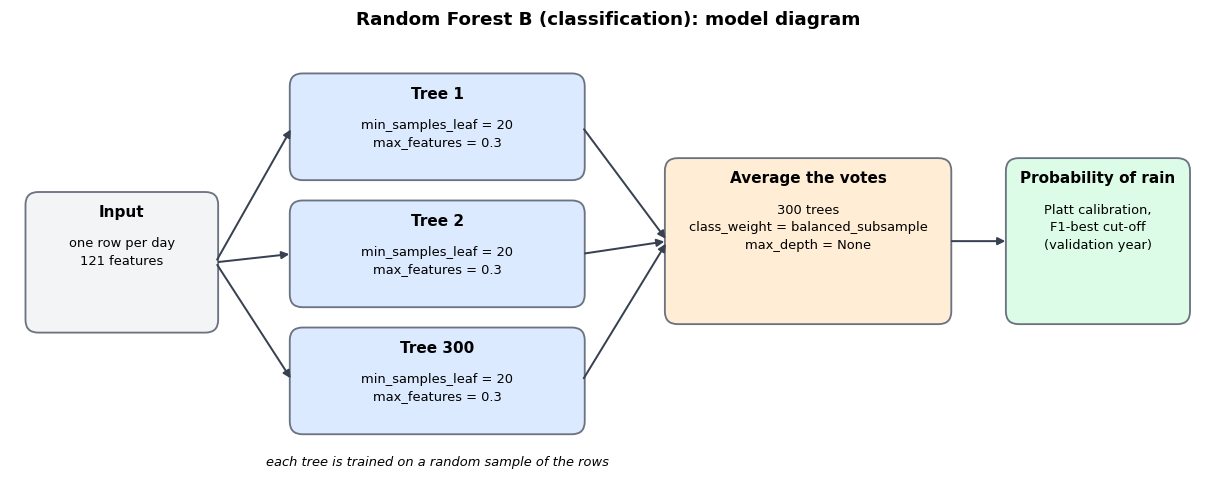

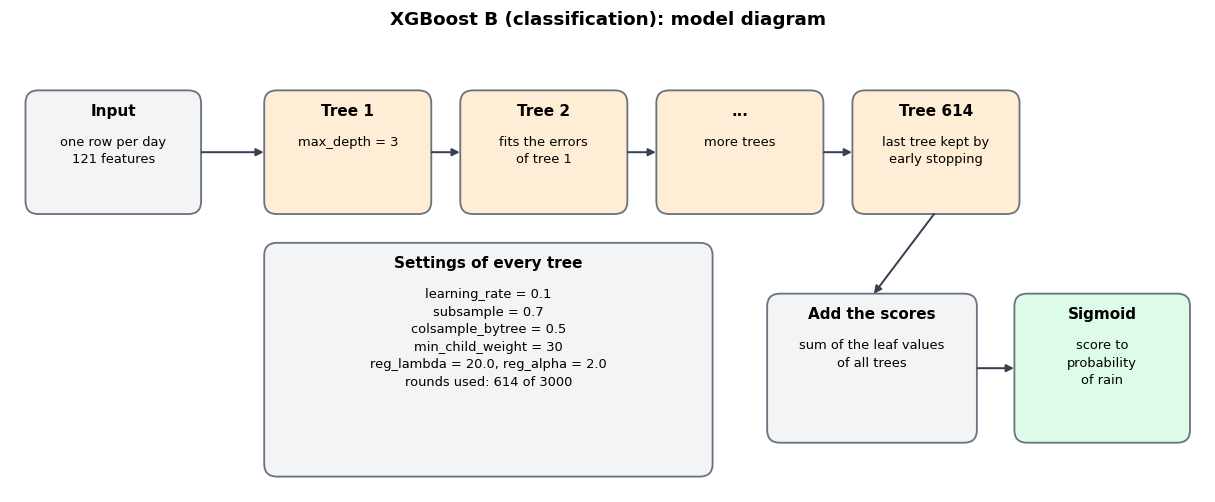

In [49]:
from matplotlib.patches import FancyBboxPatch


def box(ax, x, y, w, h, title, lines, color="#F3F4F6"):
    """Draw one rounded box with a bold title and lines of text; return the points where arrows join it."""
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.03,rounding_size=0.15", fc=color, ec="#6B7280", lw=1.2))
    ax.text(x + w / 2, y + h - 0.12, title, ha="center", va="top", fontsize=10, fontweight="bold")
    ax.text(x + w / 2, y + h - 0.50, "\n".join(lines), ha="center", va="top", fontsize=8.5, linespacing=1.45)
    return (x, y + h / 2), (x + w, y + h / 2)         # left and right edge centres


def arrow(ax, start, end):
    ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="-|>", color="#374151", lw=1.3))


def new_canvas(title, width=14, height=4.6):
    fig, ax = plt.subplots(figsize=(width, height))
    ax.set_xlim(0, width)
    ax.set_ylim(0, height)
    ax.axis("off")
    ax.set_title(title, fontsize=12, fontweight="bold")
    return fig, ax


# Random Forest B: many independent trees whose votes are averaged
p = rf_b.get_params()
fig, ax = new_canvas("Random Forest B (classification): model diagram", 14, 5.4)
_, out_in = box(ax, 0.2, 1.9, 2.2, 1.6, "Input", ["one row per day", f"{X.shape[1]} features"])
tree_edges = []
for i, label in enumerate(["Tree 1", "Tree 2", f"Tree {p['n_estimators']}"]):
    y = 3.7 - i * 1.5
    left, right = box(ax, 3.3, y, 3.4, 1.2, label, [f"min_samples_leaf = {p['min_samples_leaf']}",
                                                    f"max_features = {p['max_features']}"], "#DBEAFE")
    arrow(ax, out_in, left)
    tree_edges.append(right)
ax.text(5.0, 0.3, "each tree is trained on a random sample of the rows", ha="center", fontsize=8.5, style="italic")
vote_left, vote_right = box(ax, 7.7, 2.0, 3.3, 1.9, "Average the votes", [f"{p['n_estimators']} trees", f"class_weight = {p['class_weight']}",
                                                                      f"max_depth = {p['max_depth']}"], "#FFEDD5")
for right in tree_edges:
    arrow(ax, right, vote_left)
prob_left, _ = box(ax, 11.7, 2.0, 2.1, 1.9, "Probability of rain", ["Platt calibration,", "F1-best cut-off", "(validation year)"], "#DCFCE7")
arrow(ax, vote_right, prob_left)
plt.show()

# XGBoost B: trees added one after another, each correcting the errors of the ones before it
p = xgb_b.get_params()
rounds_used = xgb_b.best_iteration + 1
fig, ax = new_canvas("XGBoost B (classification): model diagram", 14, 5.4)
_, previous = box(ax, 0.2, 3.3, 2.0, 1.4, "Input", ["one row per day", f"{X.shape[1]} features"])
sequence = [("Tree 1", [f"max_depth = {p['max_depth']}"]), ("Tree 2", ["fits the errors", "of tree 1"]),
            ("...", ["more trees"]), (f"Tree {rounds_used}", ["last tree kept by", "early stopping"])]
for i, (label, lines) in enumerate(sequence):
    left, right = box(ax, 3.0 + i * 2.3, 3.3, 1.9, 1.4, label, lines, "#FFEDD5")
    arrow(ax, previous, left)
    previous = right
settings = [f"learning_rate = {p['learning_rate']}", f"subsample = {p['subsample']}", f"colsample_bytree = {p['colsample_bytree']}",
            f"min_child_weight = {p['min_child_weight']}", f"reg_lambda = {p['reg_lambda']}, reg_alpha = {p['reg_alpha']}",
            f"rounds used: {rounds_used} of {p['n_estimators']}"]
box(ax, 3.0, 0.2, 5.2, 2.7, "Settings of every tree", settings, "#F3F4F6")
total_left, total_right = box(ax, 8.9, 0.6, 2.4, 1.7, "Add the scores", ["sum of the leaf values", "of all trees"])
arrow(ax, (10.85, 3.3), (10.1, 2.3))               # from the last tree down to the sum
sigmoid_left, _ = box(ax, 11.8, 0.6, 2.0, 1.7, "Sigmoid", ["score to", "probability", "of rain"], "#DCFCE7")
arrow(ax, total_right, sigmoid_left)
plt.show()

## 10. Over-fitting and under-fitting check (training vs validation only)
**Loss curves (XGBoost).** The x-axis is the number of boosting rounds, the y-axis is the log-loss, with one curve for the training rows and one for the validation year.
* Over-fitting looks like a training curve that keeps falling while the validation curve flattens or turns upward.
* Under-fitting looks like both curves still high, with little gap between them.

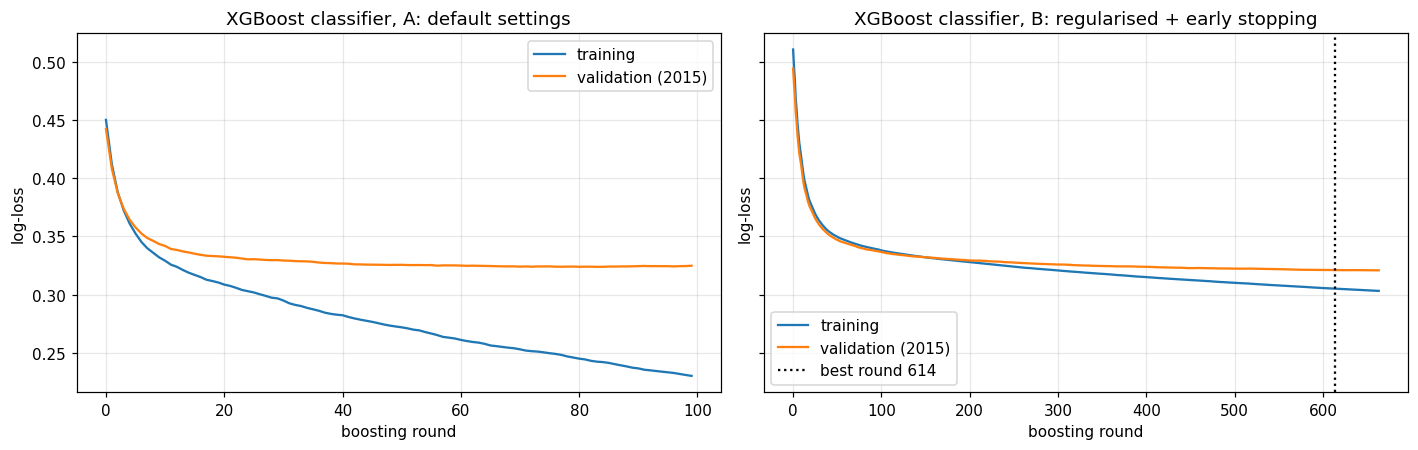

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)      # same y-axis, so the two gaps can be compared
for ax, model, title in zip(axes, (xgb_a, xgb_b), ("A: default settings", "B: regularised + early stopping")):
    curves = model.evals_result()                                   # loss after every boosting round
    ax.plot(curves["validation_0"]["logloss"], label="training")
    ax.plot(curves["validation_1"]["logloss"], label="validation (2015)")
    if model is xgb_b:                                              # mark the round chosen by early stopping
        ax.axvline(model.best_iteration, color="k", ls=":", label=f"best round {model.best_iteration + 1}")
    ax.set(title=f"XGBoost classifier, {title}", xlabel="boosting round", ylabel="log-loss")
    ax.legend()
plt.tight_layout()
plt.show()

**How to read the loss curves.**
* **A (default settings) over-fits.** The training loss keeps falling (to about 0.23) while the validation loss flattens at about 0.325 after roughly 30 rounds, and the gap widens with every round. The validation curve does not turn upward, so this is mild over-fitting, not a collapse.
* **B (regularised) is close to a good fit.** The two curves stay almost together and end about 0.015 apart (training about 0.305, validation about 0.321). Early stopping ended training at about round 610, well below the 3,000-round cap, so the stopping point comes from the validation data and not from an arbitrary limit. The validation curve is flat by then, so more rounds would not help.
* **Neither model under-fits.** Under-fitting would show both curves high and close together; here validation log-loss is far below the 0.54 of a model that always predicts the average rain rate, and the validation AUC is about 0.89 (next table).
* **Why the loss values are small and honest.** XGBoost is trained on the natural class mix (no class weights), so its probabilities are not inflated and the loss curves mean what they appear to mean.

**Train vs validation AUC for all four models.** The gap between the two columns measures over-fitting; a low validation AUC together with a low training AUC would mean under-fitting.

In [51]:
models = {"Random Forest A": rf_a, "Random Forest B": rf_b, "XGBoost A": xgb_a, "XGBoost B": xgb_b}

# AUC on the rows each model was trained on, against AUC on the validation year; a large gap means over-fitting
fit_check = pd.DataFrame({
    name: {
        "train AUC": roc_auc_score(y_train, model.predict_proba(X[train])[:, 1]),
        "validation AUC": roc_auc_score(y_val, model.predict_proba(X[val])[:, 1]),
    }
    for name, model in models.items()
}).T
fit_check["gap"] = fit_check["train AUC"] - fit_check["validation AUC"]
fit_check.round(4)

,train AUC,validation AUC,gap
Random Forest A,1.0000,0.8767,0.1233
Random Forest B,0.9558,0.8815,0.0743
XGBoost A,0.9560,0.8885,0.0675
XGBoost B,0.9085,0.8906,0.0179


**Reading the table.**
* Random Forest A scores a perfect training AUC of 1.00 because every tree is grown until its leaves are pure, so it memorises the training days. A forest's training AUC is always inflated (each tree has seen those rows), so the **validation AUC** is the number to trust.
* Regularising cuts the gap for both models: Random Forest from 0.123 to 0.075 and XGBoost from 0.068 to 0.017. The validation AUC does not fall; it rises slightly for both (Random Forest 0.877 to 0.881, XGBoost 0.889 to 0.891). That is the sign that the extra capacity of A was only memorisation.
* XGBoost B has the smallest gap (0.017) and the highest validation AUC, so it is the best-controlled model.



## 11. Probability calibration and decision threshold (validation year only)
Class weights (used by the Random Forests) push the raw probabilities upwards, and every model's scores can be slightly off. A one-variable logistic regression (Platt scaling), fitted on the validation year,
maps each model's score to a calibrated probability. The cut-off that maximises the F1 score on the validation year becomes the decision threshold.
Both are then frozen before the test period is touched.

In [52]:
def best_threshold(y, prob):
    """Cut-off with the highest F1 score."""
    precision, recall, cutoffs = precision_recall_curve(y, prob)
    f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)   # F1 at every cut-off
    return float(cutoffs[np.argmax(f1)])


calibrators = {}
thresholds = {}
for name, model in models.items():
    raw_val = model.predict_proba(X[val])[:, 1].reshape(-1, 1)                  # raw score on the validation year
    calibrators[name] = LogisticRegression(C=1e6).fit(raw_val, y_val)           # Platt scaling: score -> honest probability
    calibrated_val = calibrators[name].predict_proba(raw_val)[:, 1]
    thresholds[name] = best_threshold(y_val, calibrated_val)                    # frozen before the test period is touched

print({name: round(t, 3) for name, t in thresholds.items()})

{'Random Forest A': 0.294, 'Random Forest B': 0.245, 'XGBoost A': 0.225, 'XGBoost B': 0.227}


## 12. Test results (computed once)
Accuracy is reported next to the **always-"no rain"** accuracy because 77 % of test days are dry. ROC-AUC, PR-AUC, MCC and F1 do not depend on that imbalance in the same way.

In [53]:
def scores(y, prob, threshold):
    """All classification scores for one model: label metrics at the cut-off, ranking metrics on the probabilities."""
    label = (prob >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y, label),
        "precision": precision_score(y, label, zero_division=0),
        "recall": recall_score(y, label),
        "f1": f1_score(y, label),
        "mcc": matthews_corrcoef(y, label),
        "roc_auc": roc_auc_score(y, prob),
        "pr_auc": average_precision_score(y, prob),
        "brier": brier_score_loss(y, prob),
    }


test_prob = {}
for name, model in models.items():
    raw_test = model.predict_proba(X[test])[:, 1].reshape(-1, 1)                # the test period is used here for the first time
    test_prob[name] = calibrators[name].predict_proba(raw_test)[:, 1]           # calibrator fitted on the validation year

results = pd.DataFrame({name: scores(y_test, prob, thresholds[name]) for name, prob in test_prob.items()}).T
results.loc["always 'no rain'"] = {"accuracy": 1 - y_test.mean()}               # the trivial baseline
results.round(4)

,accuracy,precision,recall,f1,mcc,roc_auc,pr_auc,brier
Random Forest A,0.8234,0.6002,0.6852,0.6399,0.5256,0.8653,0.7008,0.1130
Random Forest B,0.8023,0.5499,0.7524,0.6354,0.5160,0.8705,0.7137,0.1114
XGBoost A,0.8233,0.5945,0.7181,0.6505,0.5379,0.8758,0.7250,0.1105
XGBoost B,0.8274,0.6022,0.7249,0.6579,0.5479,0.8778,0.7321,0.1086
always 'no rain',0.7711,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Reading the results.**
* The regularised version (B) beats the default version (A) for both models on the three measures that do not depend on a cut-off: ROC-AUC, PR-AUC and Brier score. The gains are small (about 0.002 ROC-AUC for XGBoost and 0.005 for Random Forest), which fits a validation gap that was already modest.
* Accuracy, F1 and MCC depend on the decision threshold, which was tuned on a single validation year, so they move more. Random Forest B is ahead of A on all of them. XGBoost B trades a little accuracy (81.8 % against 82.3 %) for recall (0.749 against 0.718) and is ahead of A on F1 and MCC. The ranking measures are therefore the safer guide.
* XGBoost B is the best model on ROC-AUC (0.878), PR-AUC, F1 (0.653), MCC (0.540) and Brier score (0.109). Always predicting "no rain" gives 77.1 %, so the real accuracy gain is about **5 points**, not the 80 % that raw accuracy suggests.
* About 4 in 10 predicted rain days are false alarms (precision about 0.58), and about 3 in 4 real rain days are caught (recall about 0.75). The threshold cannot make both numbers high at once.
* The Brier score (0.109 for XGBoost B) is the mean squared error of the predicted probability; lower is better, and 0 is perfect.

## 13. Comparison with the paper
The paper's Table 9 reports accuracy, precision, recall and F1 on a balanced, randomly split test set. The columns below put the
regularised models next to those figures.

In [54]:
# Figures reported in Table 9 of the paper (balanced, randomly split test set)
paper = pd.DataFrame({
    "XGBoost": {"accuracy": 0.9220, "precision": 0.9561, "recall": 0.8840, "f1": 0.9187},
    "Random Forest": {"accuracy": 0.9130, "precision": 0.9142, "recall": 0.9116, "f1": 0.9129},
}).T

# Put the paper's figures next to the regularised models of this appendix
comparison = pd.concat({
    "paper (Table 9)": paper,
    "this appendix (B)": results.loc[["XGBoost B", "Random Forest B"], ["accuracy", "precision", "recall", "f1"]]
        .rename(index={"XGBoost B": "XGBoost", "Random Forest B": "Random Forest"}),
}, axis=1)
comparison["accuracy change"] = comparison[("this appendix (B)", "accuracy")] - comparison[("paper (Table 9)", "accuracy")]
comparison.round(4)

paper (Table 9)                           this appendix (B)                           accuracy change
                     accuracy precision  recall      f1          accuracy precision  recall      f1                
XGBoost                 0.922    0.9561  0.8840  0.9187            0.8274    0.6022  0.7249  0.6579         -0.0946
Random Forest           0.913    0.9142  0.9116  0.9129            0.8023    0.5499  0.7524  0.6354         -0.1107

**Reading the comparison.** Accuracy is about 9 to 10 points below the paper's (0.82 against 0.92 for XGBoost, 0.82 against 0.91 for Random Forest), and precision is far lower (0.58 against 0.96 for XGBoost).
The numbers are not like-for-like, and the likely reasons are in the evaluation design, not in the models (section 16 measures each one):
* The paper split random rows 80/20, so each test day sat between training days of the same station. Weather on neighbouring days is strongly related, so this is far easier than forecasting an unseen future period.
* The paper's test rows were balanced to roughly half rainy days, which pushes precision up. Here the test set keeps the real 23 % rain rate.
* The paper deleted outliers with the IQR rule, which removes real storm days and changes the share of rainy days.

These differences do not prove the paper's numbers are wrong, but a forecaster would see the lower figures here, not the paper's. The paper's own LSTM scored 85.8 % accuracy in Table 9.

## 14. Is the result stable over time?
The validation year is a single year, so a result could be good by luck. The test period is split into three blocks to check that the ranking of
the models does not depend on one season.

In [55]:
test_dates = cal["Date"].iloc[test].reset_index(drop=True)
blocks = {                                                           # three six-month blocks of the test period
    "2016 Jan-Jun": (test_dates < "2016-07-01").to_numpy(),
    "2016 Jul-Dec": ((test_dates >= "2016-07-01") & (test_dates < "2017-01-01")).to_numpy(),
    "2017 Jan-Jun": (test_dates >= "2017-01-01").to_numpy(),
}

# ROC-AUC inside each block: if the ranking of the models changes between blocks, the result is not stable
stability = pd.DataFrame({
    name: {block: roc_auc_score(y_test[rows], prob[rows]) for block, rows in blocks.items()}
    for name, prob in test_prob.items()
}).T
print("ROC-AUC by test block")
stability.round(4)

ROC-AUC by test block


,2016 Jan-Jun,2016 Jul-Dec,2017 Jan-Jun
Random Forest A,0.8663,0.8591,0.8706
Random Forest B,0.8696,0.8656,0.8758
XGBoost A,0.8772,0.8720,0.8769
XGBoost B,0.8775,0.8720,0.8835


**Reading the table.** XGBoost B has the highest ROC-AUC in all three blocks (0.878, 0.873, 0.884), and Random Forest B beats Random Forest A in all three. The ranking does not depend on one season, so the result is not a one-block accident.

**Calibration (reliability) plot.** If the predicted chance of rain is honest, the points follow the diagonal.

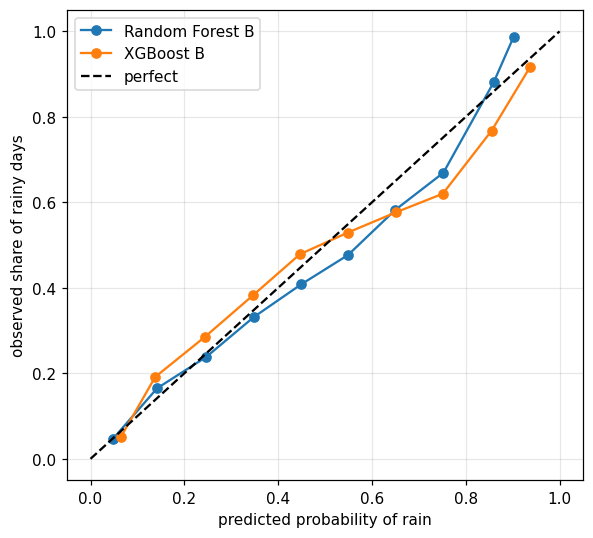

In [56]:
plt.figure(figsize=(5.5, 5))
for name in ("Random Forest B", "XGBoost B"):
    observed, predicted = calibration_curve(y_test, test_prob[name], n_bins=10)   # 10 bins of predicted probability
    plt.plot(predicted, observed, "o-", label=name)
plt.plot([0, 1], [0, 1], "k--", label="perfect")                     # honest probabilities follow this diagonal
plt.xlabel("predicted probability of rain")
plt.ylabel("observed share of rainy days")
plt.legend()
plt.tight_layout()
plt.show()

## 15. Regression: how many millimetres will fall tomorrow?
The paper also reports a regression table (Table 11), but its target was trimmed and rescaled, so its R², MAE and MSE are **not comparable** with millimetre errors here.
The same two models are trained on raw millimetres and judged against two honest references: always predicting 0 mm, and always predicting the training average.

* **Random Forest** A uses defaults; B requires at least 30 days per leaf and looks at 30 % of the features per split.
* **XGBoost** uses the Tweedie loss, which suits a target that is exactly 0 on most days and very large on a few. A is the fast high-capacity setting; B is shallow, penalised and stopped early.

In [57]:
# Regression target: rainfall in mm tomorrow, using the rows that have that value
reg_train, reg_val, reg_test = split["reg"]["train"], split["reg"]["val"], split["reg"]["test"]
y_reg = cal["y_reg"].to_numpy()
r_train, r_val, r_test = y_reg[reg_train], y_reg[reg_val], y_reg[reg_test]

# Random Forest A and B (same idea as for classification, but each leaf averages the rainfall of its days)
rf_reg_a = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    min_samples_leaf=1,
    max_features=1.0,                       # every split may look at all features
    n_jobs=2,
    random_state=SEED,
)
rf_reg_b = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=30,                    # every leaf must hold at least 30 days
    max_features=0.3,
    n_jobs=2,
    random_state=SEED,
)
# XGBoost with the Tweedie loss: suits a target that is exactly 0 on most days and very large on a few
xgb_reg_a = xgb.XGBRegressor(
    objective="reg:tweedie",
    tweedie_variance_power=1.5,             # between Poisson (1) and gamma (2)
    n_estimators=100,
    max_depth=6,
    learning_rate=0.3,
    eval_metric="tweedie-nloglik@1.5",
    tree_method="hist",
    n_jobs=2,
    random_state=SEED,
)
xgb_reg_b = xgb.XGBRegressor(
    objective="reg:tweedie",
    tweedie_variance_power=1.5,
    n_estimators=3000,              # upper limit, early stopping ends training sooner
    max_depth=3,
    learning_rate=0.05,
    subsample=0.7,
    colsample_bytree=0.5,
    min_child_weight=30,
    reg_lambda=20.0,
    reg_alpha=2.0,
    early_stopping_rounds=50,       # stop after 50 rounds without a better validation loss
    eval_metric="tweedie-nloglik@1.5",
    tree_method="hist",
    n_jobs=2,
    random_state=SEED,
)

reg_eval_sets = [(X[reg_train], r_train), (X[reg_val], r_val)]
rf_reg_a.fit(X[reg_train], r_train)
rf_reg_b.fit(X[reg_train], r_train)
xgb_reg_a.fit(X[reg_train], r_train, eval_set=reg_eval_sets, verbose=False)
xgb_reg_b.fit(X[reg_train], r_train, eval_set=reg_eval_sets, verbose=False)
print(f"XGBoost regression B stopped at round {xgb_reg_b.best_iteration + 1} of a possible {xgb_reg_b.n_estimators}")

XGBoost regression B stopped at round 1238 of a possible 3000


**Loss curves for the XGBoost regressors** (same reading as section 10).

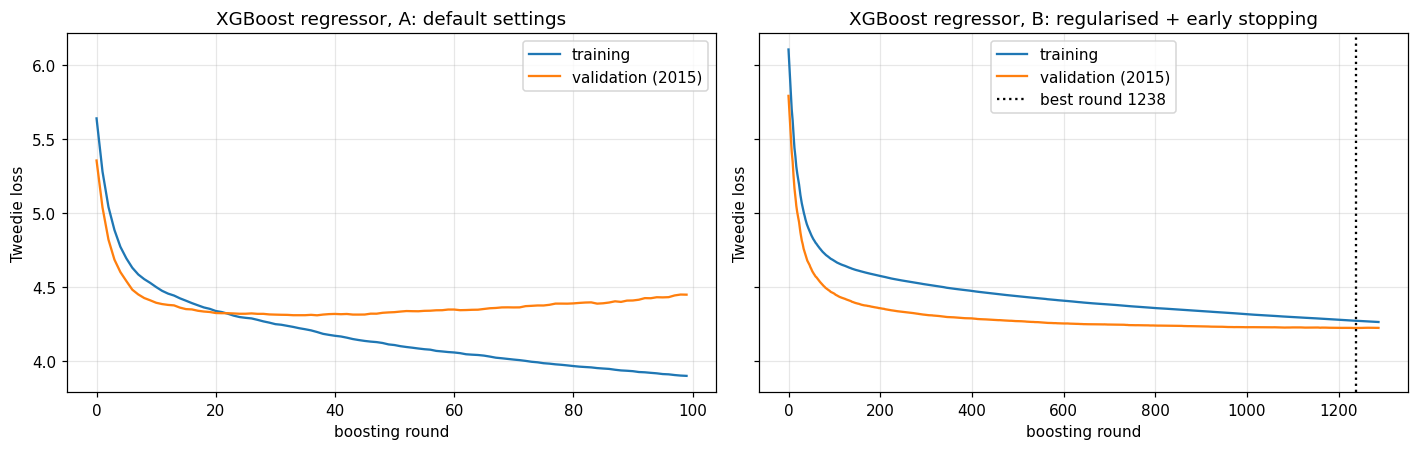

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, model, title in zip(axes, (xgb_reg_a, xgb_reg_b), ("A: default settings", "B: regularised + early stopping")):
    curves = model.evals_result()
    metric = list(curves["validation_0"])[0]                        # name of the recorded loss
    ax.plot(curves["validation_0"][metric], label="training")
    ax.plot(curves["validation_1"][metric], label="validation (2015)")
    if model.get_params()["early_stopping_rounds"]:                 # only B uses early stopping
        ax.axvline(model.best_iteration, color="k", ls=":", label=f"best round {model.best_iteration + 1}")
    ax.set(title=f"XGBoost regressor, {title}", xlabel="boosting round", ylabel="Tweedie loss")
    ax.legend()
plt.tight_layout()
plt.show()

**Test errors in millimetres (computed once).** RMSE punishes large misses, MAE treats all misses equally, and R² is the share of the variation explained (0 means no better than the training average).

In [59]:
def reg_scores(y, pred):
    """Error measures in millimetres (MAE, MSE, RMSE) and the share of variation explained (R2)."""
    mse = mean_squared_error(y, pred)
    return {"MAE": mean_absolute_error(y, pred), "MSE": mse, "RMSE": float(np.sqrt(mse)), "R2": r2_score(y, pred)}


reg_models = {
    "Random Forest A": rf_reg_a, "Random Forest B": rf_reg_b,
    "XGBoost A": xgb_reg_a, "XGBoost B": xgb_reg_b,
}
reg_results = pd.DataFrame({name: reg_scores(r_test, model.predict(X[reg_test])) for name, model in reg_models.items()}).T
reg_results.loc["always 0 mm"] = reg_scores(r_test, np.zeros_like(r_test))                  # trivial baseline 1
reg_results.loc["training mean"] = reg_scores(r_test, np.full_like(r_test, r_train.mean())) # trivial baseline 2
reg_results.round(3)

,MAE,MSE,RMSE,R2
Random Forest A,2.932,54.973,7.414,0.218
Random Forest B,2.688,51.995,7.211,0.261
XGBoost A,2.374,52.536,7.248,0.253
XGBoost B,2.411,48.276,6.948,0.313
always 0 mm,2.418,76.160,8.727,-0.083
training mean,3.684,70.314,8.385,-0.000


**Reading the regression results.**
* **Loss curves.** XGBoost A over-fits: its validation loss bottoms out at about round 35 and then rises while training keeps falling. XGBoost B has no such rise; its validation curve is flat at the end. The validation curve sits below the training curve throughout, most likely because 2015 had fewer very heavy-rain days than the training years. Both curves have levelled off, so this is not under-fitting.
* **RMSE.** XGBoost B is best at 6.91 mm (R² 0.32), about 21 % lower than always predicting 0 mm (8.73 mm). Regularising helps both models (Random Forest 7.41 to 7.22 mm).
* **MAE.** Always predicting 0 mm gives an MAE of 2.42 mm, and the models are about the same or worse (2.37 to 2.93 mm). Most days are dry, so a model that says "0" is rarely far off on the average day. The models earn their advantage on RMSE, by catching the wet days that carry the largest errors.
* **Paper.** Its R² of 0.70 to 0.76 is on a trimmed, rescaled target and cannot be compared with these millimetre errors.

### 15.1 Size of the regression models
Same counting rule as section 9.1: learned values = 2 x split nodes + leaves.

In [60]:
# Same counting rule as for the classification models (tree_summary was defined in section 9.1)
reg_size_table = pd.DataFrame({
    "Random Forest A": tree_summary(rf_reg_a),
    "Random Forest B": tree_summary(rf_reg_b),
    "XGBoost A": tree_summary(xgb_reg_a),
    "XGBoost B": tree_summary(xgb_reg_b),
}).T
reg_size_table.style.format({"depth": "{:.1f}", "trees": "{:,.0f}", "split nodes": "{:,.0f}", "leaves": "{:,.0f}", "learned values": "{:,.0f}"})

,trees,depth,split nodes,leaves,learned values
Random Forest A,100,63.2,"2,324,101","2,324,201","6,972,403"
Random Forest B,300,33.7,"431,090","431,390","1,293,570"
XGBoost A,100,6.0,"5,682","5,782","17,146"
XGBoost B,"1,238",3.0,"8,551","9,789","26,891"


**Reading the table.** The same pattern holds for regression. Random Forest A is the largest model by far (6,976,111 values), regularising cuts the forest to 1,293,423, and the XGBoost models stay small (17,146 for A and 20,843 for B). Only the trees up to the best round are counted for XGBoost B, because the last 50 rounds of early stopping are not used for prediction.

## 16. Proof: what the paper's evaluation choices do to the score
Phase 1 argued that three choices in the paper inflate its accuracy: (1) **IQR deletion** of "outliers", (2) **SMOTE before the split**, and (3) a **random** row split.
This section tests that claim on the same data. It starts from the paper's recipe and changes **one choice at a time**, always with the same two default models
(XGBoost and Random Forest) and the same 34 daily features, so that only the evaluation design changes.

| Step | IQR deletion | SMOTE | Split | Test rows |
|---|---|---|---|---|
| 1. Paper's recipe | yes, on all rows | on all rows, before the split | random 80/20 | real + synthetic |
| 2. Fix the SMOTE leak | yes | on training rows only | random 80/20 | real only |
| 3. Drop SMOTE | yes | none | random 80/20 | real only |
| 4. Keep the storm days | none | none | random 80/20 | real only |
| 5. Split by time | none | none | chronological | real only |
| 6. Add history features | none | none | chronological | real only (the final baseline) |

Every row uses the default 0.5 cut-off, with no class weights and no tuning, so the steps are comparable. The column **always "no rain"** is the accuracy of a
model that never predicts rain on that test set. **Skill** = (accuracy - always "no rain") / (1 - always "no rain") and removes the effect of the class mix.

In [61]:
from imblearn.over_sampling import SMOTE                      # needs: pip install imbalanced-learn
from sklearn.model_selection import train_test_split

# The ten continuous columns the paper trims with the IQR rule
TEN_CONTINUOUS = ["MinTemp", "MaxTemp", "Rainfall", "WindGustSpeed", "WindSpeed9am",
                  "WindSpeed3pm", "Humidity9am", "Humidity3pm", "Temp9am", "Temp3pm"]

real = cal[cal["observed"] & cal["y_cls"].notna()]                  # real, labelled days only
X_daily = daily.loc[real.index].to_numpy()                          # the 34 daily features (the paper has no history features)
y_real = real["y_cls"].to_numpy().astype(int)


def iqr_keep(frame, columns):
    """Rows inside Tukey's fences (Q1 - 1.5 IQR, Q3 + 1.5 IQR) on every column, with the fences taken from ALL rows (the paper's way)."""
    keep = np.ones(len(frame), dtype=bool)
    for col in columns:
        q1, q3 = frame[col].quantile([0.25, 0.75])
        spread = q3 - q1
        inside = frame[col].between(q1 - 1.5 * spread, q3 + 1.5 * spread) | frame[col].isna()
        keep &= inside.to_numpy()                                   # a row survives only if it is inside on every column
    return keep


keep = iqr_keep(real, TEN_CONTINUOUS)
print(f"real labelled rows: {len(real):,}")
print(f"rows deleted by the IQR rule: {(~keep).sum():,} ({(~keep).mean():.1%})")
print(f"rain-tomorrow rate among the deleted rows: {y_real[~keep].mean():.3f}  | among the kept rows: {y_real[keep].mean():.3f}")
print(f"rain-today rate among the deleted rows: {real.loc[~keep, 'RainToday'].mean():.3f}  | among the kept rows: {real.loc[keep, 'RainToday'].mean():.3f}")

real labelled rows: 142,193
rows deleted by the IQR rule: 30,748 (21.6%)
rain-tomorrow rate among the deleted rows: 0.453  | among the kept rows: 0.161
rain-today rate among the deleted rows: 0.833  | among the kept rows: 0.054


**Reading the IQR result.** The rule deletes 30,748 of the 142,193 labelled days (21.6 %). Among the deleted days 45.3 % were followed by rain and 83.3 % had rain today; among the kept days only 16.1 % and 5.4 %. So the rule throws away the wet days the model is meant to learn from and leaves a data set that is about 84 % dry.

In [62]:
def default_models():
    """The two default (version A) models, so that every step uses identical settings."""
    return {
        "XGBoost": xgb.XGBClassifier(
            n_estimators=100,
            max_depth=6,
            learning_rate=0.3,
            eval_metric="logloss",
            tree_method="hist",
            n_jobs=2,
            random_state=SEED,
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=100,
            n_jobs=2,
            random_state=SEED,
        ),
    }


def run_step(step, X_train, y_train, X_test, y_test):
    """Train both default models on the training rows and score them on the test rows (cut-off 0.5)."""
    rows, fitted = {}, {}
    for name, model in default_models().items():
        model.fit(X_train, y_train)
        prob = model.predict_proba(X_test)[:, 1]
        label = (prob >= 0.5).astype(int)                           # the same 0.5 cut-off at every step
        always_no = 1 - y_test.mean()                               # accuracy of always saying "no rain" on this test set
        accuracy = accuracy_score(y_test, label)
        rows[(step, name)] = {
            "accuracy": accuracy,
            "always no rain": always_no,
            "skill": (accuracy - always_no) / (1 - always_no),      # 0 = no better than "no rain", 1 = perfect
            "F1": f1_score(y_test, label),
            "ROC-AUC": roc_auc_score(y_test, prob),
            "test rows": len(y_test),
        }
        fitted[name] = model
    return rows, fitted


results_steps = {}

# Step 1: the paper's recipe. IQR on all rows, SMOTE on all rows, then a random 80/20 split.
X_kept, y_kept = X_daily[keep], y_real[keep]                                       # IQR deletion
X_bal, y_bal = SMOTE(random_state=SEED).fit_resample(X_kept, y_kept)               # SMOTE before the split (the leak)
is_synthetic = np.r_[np.zeros(len(y_kept), dtype=bool), np.ones(len(y_bal) - len(y_kept), dtype=bool)]   # marks invented rows
X_tr1, X_te1, y_tr1, y_te1, syn_tr1, syn_te1 = train_test_split(X_bal, y_bal, is_synthetic, test_size=0.2, random_state=SEED)
rows, models_step1 = run_step("1. Paper's recipe", X_tr1, y_tr1, X_te1, y_te1)
results_steps.update(rows)
print(f"after SMOTE: {len(y_bal):,} rows ({len(y_kept):,} real + {is_synthetic.sum():,} synthetic) | synthetic share of the test set: {syn_te1.mean():.1%}")

# Step 2: SMOTE on the training rows only, tested on real rows.
X_tr, X_te, y_tr, y_te = train_test_split(X_kept, y_kept, test_size=0.2, random_state=SEED)   # split first
X_tr_bal, y_tr_bal = SMOTE(random_state=SEED).fit_resample(X_tr, y_tr)                         # then SMOTE the training part only
rows, _ = run_step("2. Fix the SMOTE leak", X_tr_bal, y_tr_bal, X_te, y_te)
results_steps.update(rows)

# Step 3: no SMOTE at all.
rows, _ = run_step("3. Drop SMOTE", X_tr, y_tr, X_te, y_te)
results_steps.update(rows)

# Step 4: no IQR deletion, so the storm days stay.
X_tr, X_te, y_tr, y_te = train_test_split(X_daily, y_real, test_size=0.2, random_state=SEED)
rows, _ = run_step("4. Keep the storm days", X_tr, y_tr, X_te, y_te)
results_steps.update(rows)

# Step 5: split by time (train up to 2014, test from 2016, one day dropped before the boundary).
day = real["Date"].to_numpy()
by_time_train = day <= np.datetime64(TRAIN_END - one_day)
by_time_test = day >= np.datetime64(TEST_START)
rows, _ = run_step("5. Split by time", X_daily[by_time_train], y_real[by_time_train], X_daily[by_time_test], y_real[by_time_test])
results_steps.update(rows)

# Step 6: add the history features (the final baseline of this appendix, default settings).
rows, _ = run_step("6. Add history features", X[train], y_cls[train], X[test], y_cls[test])
results_steps.update(rows)

step_table = pd.DataFrame(results_steps).T                          # one row per step and model
step_table.index.names = ["step", "model"]
step_table.round(4)

after SMOTE: 187,000 rows (111,445 real + 75,555 synthetic) | synthetic share of the test set: 40.5%


accuracy  always no rain   skill      F1  ROC-AUC  test rows
step                    model                                                                      
1. Paper's recipe       XGBoost          0.9273          0.5006  0.8544  0.9247   0.9766    37400.0
                        Random Forest    0.9325          0.5006  0.8648  0.9331   0.9837    37400.0
2. Fix the SMOTE leak   XGBoost          0.8782          0.8409  0.2348  0.5295   0.8730    22289.0
                        Random Forest    0.8664          0.8409  0.1607  0.5594   0.8745    22289.0
3. Drop SMOTE           XGBoost          0.8791          0.8409  0.2405  0.5239   0.8780    22289.0
                        Random Forest    0.8792          0.8409  0.2408  0.4828   0.8746    22289.0
4. Keep the storm days  XGBoost          0.8599          0.7786  0.3671  0.6406   0.8912    28439.0
                        Random Forest    0.8605          0.7786  0.3698  0.6284   0.8886    28439.0
5. Split by time        XGBoost          0.8443          0.7711  0.3199  0.6122   0.8703    25974.0
                        Random Forest    0.8436          0.7711  0.3169  0.5899   0.8660    25974.0
6. Add history features XGBoost          0.8497          0.7711  0.3433  0.6251   0.8758    25974.0
                        Random Forest    0.8460          0.7711  0.3271  0.5878   0.8611    25974.0

**Reading the ladder.**
* **Step 1 reproduces the paper's headline** (92.7 % for XGBoost, 93.3 % for Random Forest, against 92.2 % and 91.3 % in the paper), although the baseline of "always no rain" is only 50 % on that test set.
* **Fixing the SMOTE leak (step 2) causes the biggest fall**: accuracy drops to 87.8 % for XGBoost and the skill from 0.85 to 0.23. SMOTE adds no real skill, because dropping it (step 3) gives the same 87.9 %.
* **Keeping the storm days (step 4) makes the test harder but the model better**: the baseline falls to 77.9 %, the skill rises to 0.37 and ROC-AUC rises to 0.891.
* **A time split (step 5) is harder than a random split**: skill 0.37 to 0.32 and ROC-AUC 0.891 to 0.870. My history features (step 6) win back a little (skill 0.34).
* **Overall**, the same default models score 92.7 % under the paper's recipe and 85.0 % under a fair one, and the skill falls from 0.85 to 0.34.

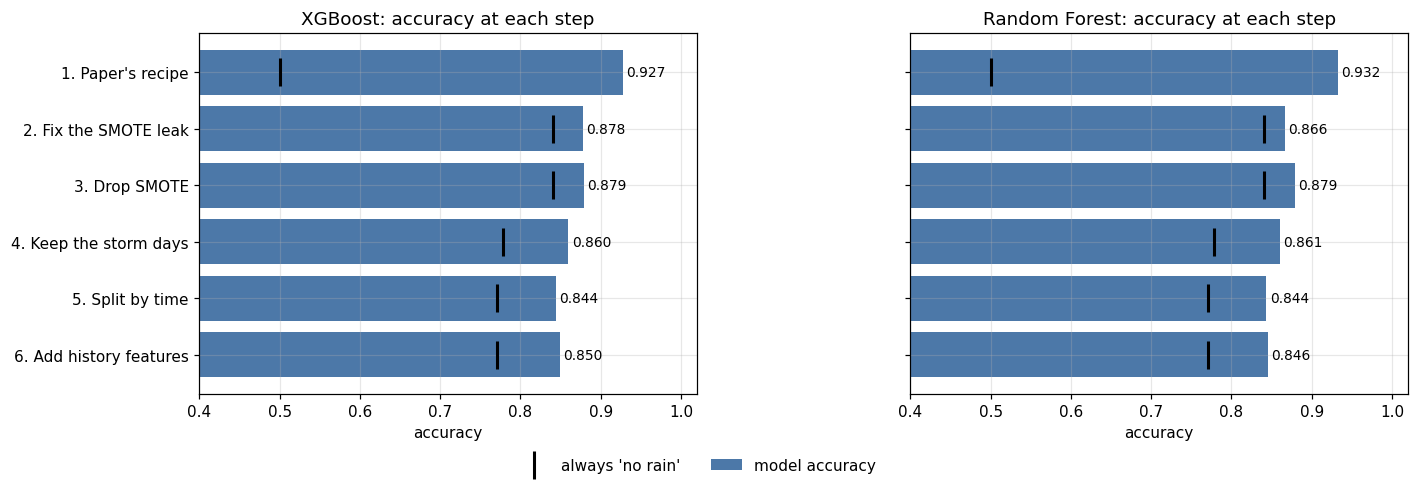

In [63]:
# Accuracy at each step; the black mark is the accuracy of always predicting "no rain" on that step's test set
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, model_name in zip(axes, ("XGBoost", "Random Forest")):
    part = step_table.xs(model_name, level="model")
    positions = np.arange(len(part))
    ax.barh(positions, part["accuracy"], color="#4C78A8", label="model accuracy")
    ax.plot(part["always no rain"], positions, "k|", markersize=18, markeredgewidth=2, label="always 'no rain'")
    for position_i, value in zip(positions, part["accuracy"]):
        ax.text(value + 0.004, position_i, f"{value:.3f}", va="center", fontsize=9)       # print the accuracy on each bar
    ax.set_yticks(positions)
    ax.set_yticklabels(part.index)
    ax.set_xlim(0.4, 1.02)
    ax.set(title=f"{model_name}: accuracy at each step", xlabel="accuracy")
axes[0].invert_yaxis()                                              # step 1 at the top (the axis is shared)
axes[0].legend(loc="upper center", bbox_to_anchor=(1.0, -0.14), ncol=2, frameon=False)   # legend below, clear of the bars
plt.tight_layout()
plt.show()

**Is the gain in step 1 real? A direct check.** In step 1 the model is scored on a test set that is partly synthetic. If synthetic rows are easy because they are
interpolations of training rows, the same model should score much higher on them than on real rows.

In [64]:
# Score the step 1 models separately on the real and the synthetic rows of their own test set
probe_rows = {}
for model_name, model in models_step1.items():
    label = model.predict(X_te1)
    probe_rows[model_name] = {
        "accuracy on real test rows": accuracy_score(y_te1[~syn_te1], label[~syn_te1]),
        "accuracy on synthetic test rows": accuracy_score(y_te1[syn_te1], label[syn_te1]),
        "synthetic share of test set": syn_te1.mean(),
    }
pd.DataFrame(probe_rows).T.round(4)

,accuracy on real test rows,accuracy on synthetic test rows,synthetic share of test set
XGBoost,0.8798,0.9970,0.4048
Random Forest,0.8984,0.9834,0.4048


**Reading the check.** The models score 99.7 % (XGBoost) and 98.4 % (Random Forest) on the synthetic rows but only 88.0 % and 89.9 % on the real rows of the same test set, and 40.5 % of that test set is synthetic. A synthetic row is a blend of two real training rows, so the model has effectively seen it already. This is the leak made visible.

## 17. Conclusions and limitations
**What the baselines show**
* Two simple tree baselines, trained in minutes on a laptop, reach **81 to 82 % accuracy** and a **ROC-AUC of 0.87 to 0.88** on a future test period. The best on ranking, XGBoost B, has 81.8 % accuracy, 0.878 ROC-AUC and 0.653 F1.
* Regularising (B) shrinks the gap between training and validation for both models (XGBoost train-validation AUC gap 0.068 to 0.017) and gives small gains in ROC-AUC, PR-AUC and Brier score. Early stopping places XGBoost's stopping round at 612 of 3,000, set by the validation data instead of an arbitrary limit.
* The paper's 91 to 92 % accuracy is reproduced when its evaluation recipe is used (92.7 % for XGBoost, section 16) and falls to about 85 % when the leakage and the outlier deletion are removed; the skill falls from 0.85 to 0.34. The accuracy is a product of the evaluation design, not of a better model.
* For rainfall in millimetres, the best baseline cuts RMSE by about 21 % against always predicting 0 mm, but explains only about a third of the variation (R² 0.32).

**Limitations**
* The B settings were picked from a few candidates using the 2015 validation year, which is also used for early stopping, calibration and the decision threshold. This can make validation scores slightly optimistic, which is why the test period was kept separate and used once.
* One random seed per model and one 18-month test period. The three-block check in section 14 supports stability but is not a full cross-validation.
* The authors' LSTM was not retrained here. It is compared through the figures the paper reports (Table 9: 85.8 % accuracy).
* The history features and the 15-day-record rule are my additions, not the paper's.